In [ ]:
!pip install -U transformers datasets accelerate scikit-learn matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 53.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 41.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 8.8 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 23.0.1
    Uninstalling pyarrow-23.0.1:
      Successfully uninstalled pyarrow-23.0.1
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0
    Uninstalling matplotlib-3.10.0:
      Successfully uninstalled matplotlib-3.10.0
  Attempting uninstall: datasets
    Found existing installation: datasets 4.8.5
    Uninstalling dat

In [1]:
# Imports
import numpy as np
import torch
import matplotlib.pyplot as plt

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [2]:
# Load IMDb dataset
dataset = load_dataset("stanfordnlp/imdb")

print(dataset)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [3]:
# Check one example
print(dataset["train"][0])
print("\n0 = Negative, 1 = Positive")

{'text': 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far be

In [4]:
# IMPORTANT: create the SMALL datasets BEFORE tokenization
train_dataset = (
    dataset["train"]
    .shuffle(seed=42)
    .select(range(2000))
)

test_dataset = (
    dataset["test"]
    .shuffle(seed=42)
    .select(range(500))
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 2000
Testing samples: 500


In [5]:
# BERT model settings
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 256

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded.")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded.


In [6]:
# Convert review text into BERT tokens
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True
)

tokenized_test = test_dataset.map(
    tokenize_function,
    batched=True
)

print("Tokenized train:", len(tokenized_train))
print("Tokenized test:", len(tokenized_test))

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Tokenized train: 2000
Tokenized test: 500


In [7]:
# Safety check: these MUST be 2000 and 500
assert len(tokenized_train) == 2000
assert len(tokenized_test) == 500

print("Dataset sizes are correct.")

Dataset sizes are correct.


In [8]:
# Dynamic padding pads only to the longest item in each batch
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

id2label = {
    0: "NEGATIVE",
    1: "POSITIVE"
}

label2id = {
    "NEGATIVE": 0,
    "POSITIVE": 1
}

In [9]:
# Load pretrained BERT with a new 2-class classification head
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id
)

print("Model loaded.")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded.


In [10]:
# Metric used during evaluation
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions)
    }

In [11]:
# Training settings
training_args = TrainingArguments(
    output_dir="./bert_small_sentiment",

    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    num_train_epochs=2,
    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="no",

    logging_steps=50,
    report_to="none",

    # Avoid CPU pin-memory warning
    dataloader_pin_memory=torch.cuda.is_available(),

    # Used only when CUDA GPU is available
    fp16=torch.cuda.is_available()
)

In [12]:
# Create Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Expected training steps: about 500")

Expected training steps: about 500


In [13]:
# Fine-tune BERT
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.317559,0.288551,0.872000
2,0.218915,0.338203,0.892000


TrainOutput(global_step=500, training_loss=0.33822988319396974, metrics={'train_runtime': 71.0315, 'train_samples_per_second': 56.313, 'train_steps_per_second': 7.039, 'total_flos': 525675333058080.0, 'train_loss': 0.33822988319396974, 'epoch': 2.0})

In [14]:
# Evaluate the trained model
results = trainer.evaluate()

print("Evaluation results:")
print(results)

Training Loss,Validation Loss,Epoch,Accuracy
0.218915,0.338203,2,0.892000


Evaluation results:
{'eval_loss': 0.33820250630378723, 'eval_accuracy': 0.892}


In [15]:
# Predict on the SAME 500-example tokenized test dataset
prediction_output = trainer.predict(tokenized_test)

predicted_labels = np.argmax(
    prediction_output.predictions,
    axis=1
)

true_labels = np.array(test_dataset["label"])

print("True labels:", len(true_labels))
print("Predicted labels:", len(predicted_labels))

# Prevent the old 500 vs 25000 error
assert len(true_labels) == len(predicted_labels) == 500

True labels: 500
Predicted labels: 500


In [16]:
# Precision, Recall, F1-score and Accuracy
print(
    classification_report(
        true_labels,
        predicted_labels,
        labels=[0, 1],
        target_names=["Negative", "Positive"],
        digits=4
    )
)

              precision    recall  f1-score   support

    Negative     0.9098    0.8740    0.8916       254
    Positive     0.8750    0.9106    0.8924       246

    accuracy                         0.8920       500
   macro avg     0.8924    0.8923    0.8920       500
weighted avg     0.8927    0.8920    0.8920       500



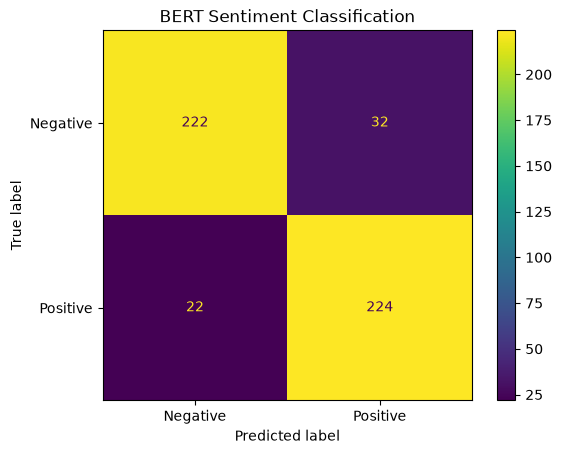

In [17]:
# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    true_labels,
    predicted_labels,
    labels=[0, 1],
    display_labels=["Negative", "Positive"]
)

plt.title("BERT Sentiment Classification")
plt.show()

In [18]:
# Function for predicting your own review
def predict_sentiment(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    )

    inputs = {
        key: value.to(model.device)
        for key, value in inputs.items()
    }

    model.eval()

    with torch.no_grad():
        outputs = model(**inputs)

    probabilities = torch.softmax(outputs.logits, dim=1)
    predicted_id = probabilities.argmax(dim=1).item()
    confidence = probabilities[0][predicted_id].item()

    return {
        "text": text,
        "sentiment": model.config.id2label[predicted_id],
        "confidence": round(confidence * 100, 2)
    }

In [19]:
# Test the model
print(
    predict_sentiment(
        "This movie was fantastic. I loved the story and acting."
    )
)

print(
    predict_sentiment(
        "This movie was boring and a complete waste of time."
    )
)

{'text': 'This movie was fantastic. I loved the story and acting.', 'sentiment': 'POSITIVE', 'confidence': 99.3}
{'text': 'This movie was boring and a complete waste of time.', 'sentiment': 'NEGATIVE', 'confidence': 98.61}


In [20]:
# Save the final model
SAVE_PATH = "./final_bert_sentiment"

model.save_pretrained(SAVE_PATH)
tokenizer.save_pretrained(SAVE_PATH)

print("Model saved to:", SAVE_PATH)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: ./final_bert_sentiment
